In [1]:
from pathlib import Path
import pandas as pd
from findingampa.utils.analysis import active_zonogram
import numpy as np

In [2]:
tomograms = pd.DataFrame([
    #{"name": "20231026_HippAu_26", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_116", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_198", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-1_15", "Label": "15F1", "active_zone": {"pre":[1], "post":[0]}},
    #{"name": "20231017_HippAu_132", "Label": "15F1"},
    {"name": "20231017_EGmilled24-2_68", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_30", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_34", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_183", "Label": "15F1"},
    #{"name": "20240624_HippWaffle_36", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_61", "Label": "15F1"},
    #{"name": "20231017_EGmilled24-2_60", "Label": "15F1"},
    #{"name": "20240920_HippWaffle_129", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_136", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_148", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_115", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_74", "Label": "5F11"},
    #{"name": "20240822_HippWaffle_31", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_113", "Label": "5F11"},
    #{"name": "20241018_HippWaffleDual_117", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_127", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_166", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_182", "Label": "15F1and5F11"},
    #{"name": "20240820_HippWaffle_97", "Label": "15F1and5F11"},
    #{"name": "20240819_HippWaffle_135", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_177", "Label": "15F1and5F11"},
])

20231017_EGmilled24-2_68
15F1
Pre: 3 Post: 1 Potential active zones: 3
[(0, 0), (1, 0), (2, 0)]


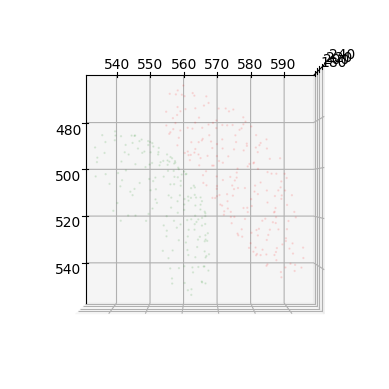

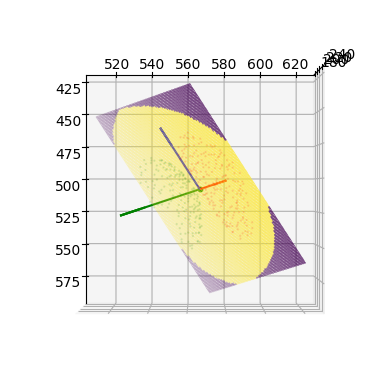

torch.Size([59, 151, 145])
torch.Size([151, 145])
tensor(0.0059)
tensor(0.0197)


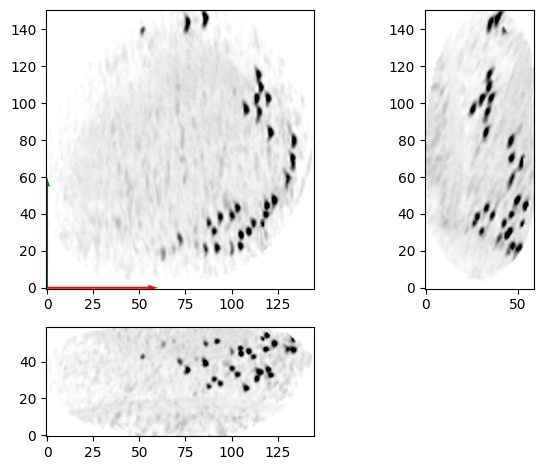

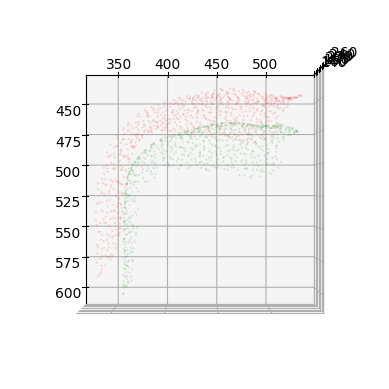

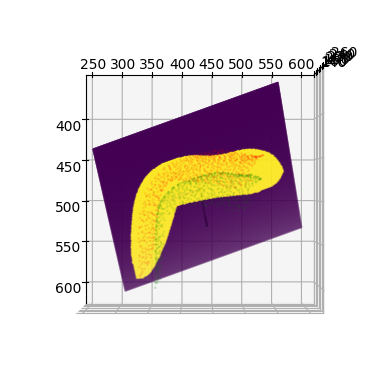

torch.Size([189, 205, 299])
torch.Size([205, 299])
tensor(0.0022)
tensor(0.0137)


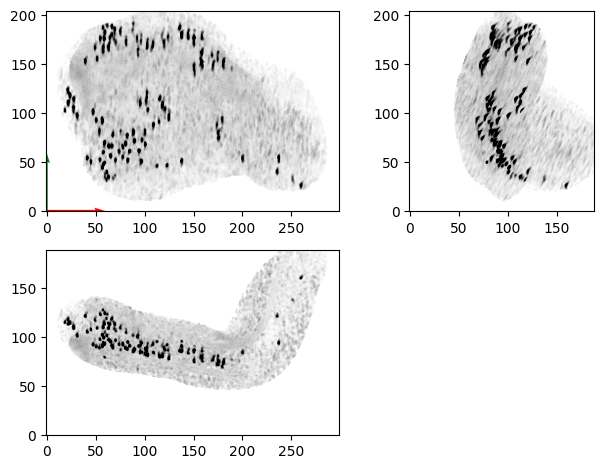

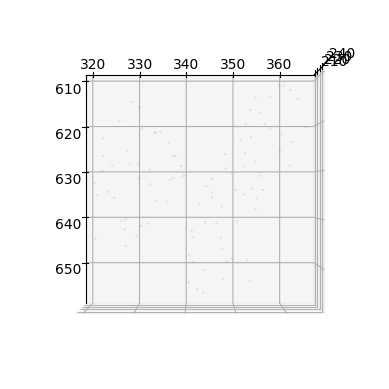

Failed to create coordinate system for active zone 2: Cannot take a larger sample than population when 'replace=False'


In [3]:
import mrcfile
import json
for tomo in tomograms.itertuples():
    name = tomo.name
    label = tomo.Label

    path = list(Path(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/best_alignment/aunps/").glob("*.glb"))
    if len(path) == 0:
        print(f"File {path} does not exist")
        continue
    path = path[0]
    print(name)
    print(label)
    try:
        return_data = active_zonogram(path.parent.parent.parent)
    except Exception as e:
        print(e)
        continue
    for i,rd in enumerate(return_data):
        mrcfile.write(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/best_alignment/aunps/active_zonogram_{i}.mrc", rd[2].numpy(), overwrite=True)
        np.save(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/best_alignment/aunps/active_zonogram_{i}.npy",{"cs": rd[0], "center": rd[1]}, allow_pickle=True)
   